# TDE 04 — Etapa final do projeto
## Análise de Revisões de Compras (Flipkart Laptop Reviews)

Continuação do projeto do **TDE 01** (EDA do dataset de reviews de laptops da Flipkart).

**Discentes:** Maria Taliciane Pereira da Silva, Wesley Furtado Pessoa, Michel Gomes Pinheiro, Ingrid Sampaio Angelim do Nascimento,
Moryak Samyak Arrais Benicio, José Daniel Macêdo Fechine, Clara Sobreira Vidal e Lia Costa Andrade

**Professor:** Alexandro Oliveira Alexandrino · **Disciplina:** Inteligência Artificial

**Problema:** prever a **nota (rating de 1 a 5)** que o cliente deu, a partir do **texto da avaliação** (`review`). É uma **classificação multiclasse** com 5 classes.

O que o TDE 04 pede e onde está:

| Pedido | Seção |
|---|---|
| Análise da base | Seção 2 |
| Baseline (algoritmos vistos em sala, sem otimização) | Seção 3 |
| SVM, Redes Neurais e Random Forest | Seção 4 |
| Modelos não estudados em sala | Seção 5 (Gradient Boosting com XGBoost e KNN) |
| Comparação dos modelos e modelo final | Seção 6 |

## 1. Carregando os dados

In [ ]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from collections import Counter
import re
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

In [ ]:
if os.path.exists("laptops_dataset_final_600.csv"):
    df = pd.read_csv("laptops_dataset_final_600.csv")
else:
    import kagglehub
    path = kagglehub.dataset_download("gitadityamaddali/flipkart-laptop-reviews")
    df = pd.read_csv(glob.glob(os.path.join(path, "*.csv"))[0])

print("Formato:", df.shape)
df[["review", "rating"]].head()

Formato: (24113, 7)


,review,rating
0,"Loved it, it's my first MacBook that I earned ...",5
1,Battery lasted longer than my first relationsh...,5
2,Such a great deal.. very happy with the perfor...,5
3,"Awesome build quality and very good display, b...",4
4,When i ordered and came to know about seller r...,5


## 2. Análise da base
Cada linha é uma avaliação de um laptop: nota de 1 a 5 (`rating`), um título curto (`title`) e o texto (`review`).

### 2.1 Distribuição das notas
As classes são **desbalanceadas**: a nota 5 domina. Por isso, além da **acurácia**, usamos o **F1-macro** (média do F1 das 5 notas),
que dá o mesmo peso a cada nota. Um modelo que só chuta "5" tem acurácia alta, mas F1-macro baixo.

,qtd,%
rating,,
1,1809,7.5
2,668,2.8
3,2035,8.4
4,5629,23.3
5,13972,57.9


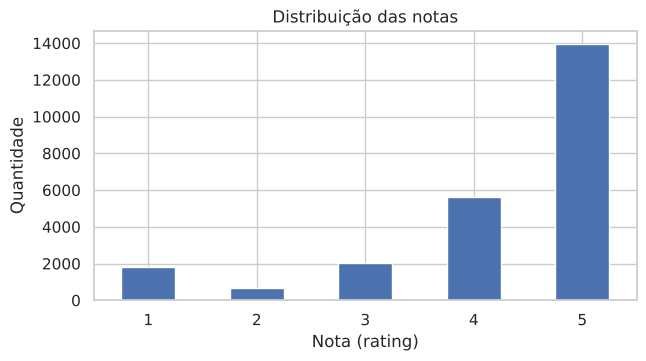

In [ ]:
dist = df["rating"].value_counts().sort_index()
display(pd.DataFrame({"qtd": dist, "%": (dist / len(df) * 100).round(1)}))

ax = dist.plot.bar(figsize=(7, 3.5), color="#4c72b0", rot=0)
ax.set_xlabel("Nota (rating)"); ax.set_ylabel("Quantidade"); ax.set_title("Distribuição das notas")
plt.show()

### 2.2 Tamanho do texto por nota

rating,1,2,3,4,5
mediana de palavras,12.0,10.0,11.0,9.0,7.0


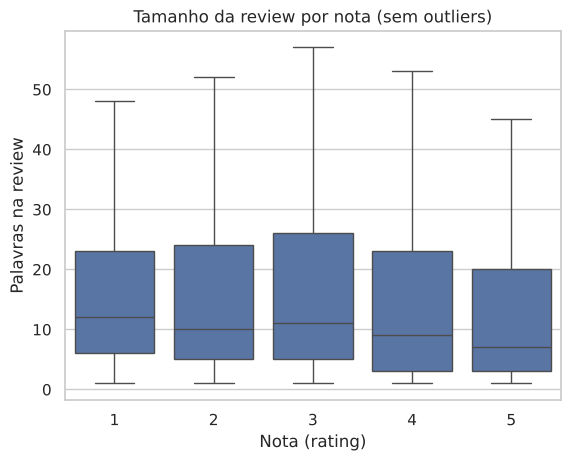

In [ ]:
df["palavras"] = df["review"].astype(str).str.split().apply(len)
display(df.groupby("rating")["palavras"].median().rename("mediana de palavras").to_frame().T)

ax = sns.boxplot(x="rating", y="palavras", data=df, showfliers=False, color="#4c72b0")
ax.set_xlabel("Nota (rating)"); ax.set_ylabel("Palavras na review"); ax.set_title("Tamanho da review por nota (sem outliers)")
plt.show()

As avaliações de nota 5 são as mais curtas (muitas são só "Good", "Nice product"). Quem dá nota baixa costuma escrever mais, explicando o problema.

### 2.3 Palavras mais frequentes: nota 1 × nota 5

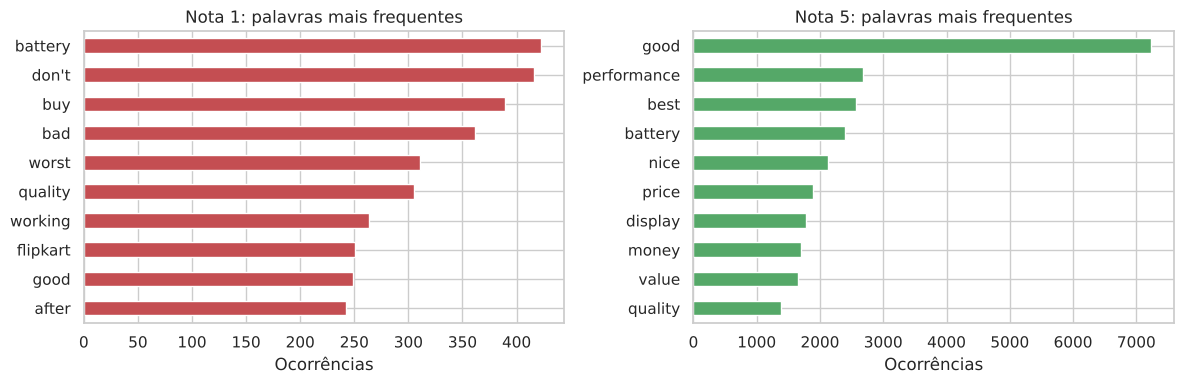

In [ ]:
STOPWORDS = {"the", "a", "an", "is", "it", "to", "and", "for", "of", "in", "this", "that", "i", "my", "with", "on", "very",
             "so", "but", "as", "was", "are", "be", "have", "has", "not", "at", "you", "its", "it's", "laptop", "product", "read", "more"}

def top_palavras(nota, n=10):
    textos = df.loc[df["rating"] == nota, "review"].astype(str).str.lower()
    palavras = [p for t in textos for p in re.findall(r"[a-z']+", t) if p not in STOPWORDS and len(p) > 2]
    return pd.Series(dict(Counter(palavras).most_common(n)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, nota, cor in zip(axes, [1, 5], ["#c44e52", "#55a868"]):
    top_palavras(nota)[::-1].plot.barh(ax=ax, color=cor)
    ax.set_title(f"Nota {nota}: palavras mais frequentes"); ax.set_xlabel("Ocorrências")
plt.tight_layout(); plt.show()

O vocabulário muda bastante entre as notas extremas: "good", "best", "nice", "value for money" na nota 5; "bad", "worst", "don't buy", "not working" na nota 1. Palavras como "battery" e "quality" aparecem nas duas, porque são o assunto da review, e não a opinião.
É essa diferença que os modelos vão aprender a partir do texto. As notas intermediárias (2, 3, 4) misturam os dois vocabulários, o que as torna mais difíceis.

## 3. Preparação dos dados e baseline

### 3.1 Preparação do texto
* **Remoção de repetições:** como visto na EDA, muitas avaliações têm exatamente o mesmo texto e a mesma nota (ex.: "Good", "Nice product").
  Se o mesmo texto ficar no treino e no teste, o modelo só "decora" a resposta.
* **Entrada:** apenas o texto da `review`. Não usamos o `title`, porque na Flipkart ele é uma frase pronta escolhida junto com a nota
  ("Terrible product", "Fabulous!"), o que entregaria a resposta ao modelo.
* **Divisão:** 80% treino e 20% teste, **estratificada** (mantém a proporção das notas).
* **TF-IDF:** transforma cada texto num vetor numérico. Cada coluna é uma palavra (ou par de palavras) e o valor indica o quanto ela é importante naquele texto.

In [ ]:
antes = len(df)
df = df.drop_duplicates(subset=["review", "rating"]).reset_index(drop=True)
print(f"Avaliações repetidas removidas: {antes - len(df)} | restam {len(df)}")

X = df["review"].astype(str)
y = df["rating"]
X_train_txt, X_test_txt, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

tfidf = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=5000)
X_train = tfidf.fit_transform(X_train_txt)
X_test = tfidf.transform(X_test_txt)
print(f"Treino: {X_train.shape[0]} textos | Teste: {X_test.shape[0]} textos | {X_train.shape[1]} termos")

resultados = []
def avaliar(modelo, nome):
    pred = modelo.predict(X_test)
    r = {"Modelo": nome, "Acurácia": accuracy_score(y_test, pred), "F1-macro": f1_score(y_test, pred, average="macro")}
    resultados.append(r)
    print(f"{nome}: acurácia = {r['Acurácia']:.3f} | F1-macro = {r['F1-macro']:.3f}")

Avaliações repetidas removidas: 12650 | restam 11463


Treino: 9170 textos | Teste: 2293 textos | 5000 termos


### 3.2 Baseline (algoritmos vistos em sala, sem otimização)
* **Dummy:** sempre prevê a classe mais frequente (nota 5).
* **Árvore de Decisão** e **Regressão Logística** com os parâmetros padrão.

In [ ]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
avaliar(dummy, "Dummy (classe mais frequente)")

arvore = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
avaliar(arvore, "Árvore de Decisão")

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)
avaliar(logreg, "Regressão Logística")

Dummy (classe mais frequente): acurácia = 0.556 | F1-macro = 0.143


Árvore de Decisão: acurácia = 0.520 | F1-macro = 0.365


Regressão Logística: acurácia = 0.640 | F1-macro = 0.400


## 4. Modelos vistos em sala: SVM, Rede Neural e Random Forest

### 4.1 SVM
O SVM procura a fronteira que separa as classes com a **maior margem** possível. Os pontos mais próximos da fronteira são os **vetores de suporte**: só eles definem o modelo.

Usamos o **kernel linear**, adequado para texto: o TF-IDF tem milhares de colunas e, nesse espaço, uma fronteira reta já separa bem as classes.
`class_weight="balanced"` dá mais peso às notas raras.

In [ ]:
svm = SVC(kernel="linear", C=1, class_weight="balanced").fit(X_train, y_train)
avaliar(svm, "SVM (linear)")

SVM (linear): acurácia = 0.544 | F1-macro = 0.422


### 4.2 Rede Neural (MLP)
Uma **rede neural MLP** tem camadas de neurônios: cada um faz uma soma ponderada das entradas e aplica uma função de ativação (ReLU).
Usamos uma camada oculta com 64 neurônios. `early_stopping=True` para o treino quando o erro de validação para de melhorar, evitando decorar o treino.

In [ ]:
mlp = MLPClassifier(hidden_layer_sizes=(64,), early_stopping=True, max_iter=200, random_state=SEED).fit(X_train, y_train)
avaliar(mlp, "Rede Neural (MLP)")

Rede Neural (MLP): acurácia = 0.645 | F1-macro = 0.414


### 4.3 Random Forest (vista em sala, na aula de Ensembles)
Treina muitas árvores de decisão, cada uma com uma amostra diferente dos dados; a previsão final é a **votação** entre elas. Isso reduz o
overfitting.

In [ ]:
rf = RandomForestClassifier(n_estimators=200, class_weight="balanced", n_jobs=-1, random_state=SEED).fit(X_train, y_train)
avaliar(rf, "Random Forest")

Random Forest: acurácia = 0.581 | F1-macro = 0.427


## 5. Modelos não estudados em sala

### 5.1 Gradient Boosting (XGBoost)
Em sala vimos boosting com o **AdaBoost**, que dá mais peso aos exemplos errados. O **Gradient Boosting** treina árvores pequenas
**em sequência**, e cada nova árvore aprende diretamente o **erro que sobrou** das anteriores. Usamos a biblioteca **XGBoost**.

In [ ]:
class XGBNotas(XGBClassifier):
    def fit(self, X, y, **kw):
        return super().fit(X, np.asarray(y) - 1, **kw)
    def predict(self, X):
        return super().predict(X) + 1

xgb = XGBNotas(n_estimators=300, learning_rate=0.1, max_depth=6, tree_method="hist", n_jobs=-1, random_state=SEED).fit(X_train, y_train)
avaliar(xgb, "Gradient Boosting (XGBoost)")

Gradient Boosting (XGBoost): acurácia = 0.638 | F1-macro = 0.412


### 5.2 KNN (k vizinhos mais próximos)
Para classificar uma review, o KNN procura as **k reviews mais parecidas** no treino e faz uma **votação** entre as notas delas. Não há um treino de verdade: o modelo só guarda os dados.
Usamos k = 15, a **distância por cosseno** (mede se dois textos usam as mesmas palavras, independentemente do tamanho) e vizinhos mais próximos pesando mais.

In [ ]:
knn = KNeighborsClassifier(n_neighbors=15, weights="distance", metric="cosine").fit(X_train, y_train)
avaliar(knn, "KNN")

KNN: acurácia = 0.604 | F1-macro = 0.377


## 6. Comparação dos modelos e modelo final
Todos avaliados no **mesmo conjunto de teste**. O critério principal é o **F1-macro**, por causa do desbalanceamento das notas.

,Acurácia,F1-macro
Modelo,,
Random Forest,0.581,0.427
SVM (linear),0.544,0.422
Rede Neural (MLP),0.645,0.414
Gradient Boosting (XGBoost),0.638,0.412
Regressão Logística,0.640,0.400
KNN,0.604,0.377
Árvore de Decisão,0.520,0.365
Dummy (classe mais frequente),0.556,0.143


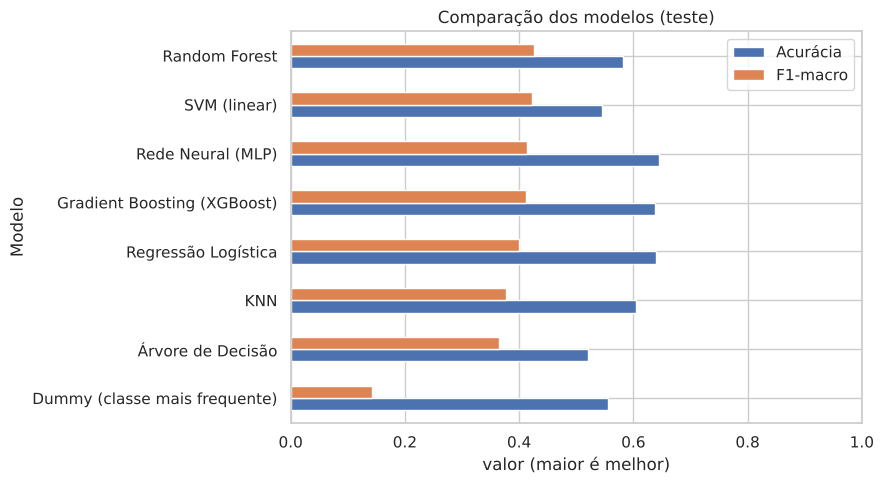

In [ ]:
comp = pd.DataFrame(resultados).set_index("Modelo").sort_values("F1-macro", ascending=False)
display(comp.round(3))

ax = comp[["Acurácia", "F1-macro"]].iloc[::-1].plot.barh(figsize=(9, 5))
ax.set_xlim(0, 1); ax.set_title("Comparação dos modelos (teste)"); ax.set_xlabel("valor (maior é melhor)")
plt.tight_layout(); plt.show()

Modelo final: Random Forest



              precision    recall  f1-score   support

           1      0.549     0.760     0.637       208
           2      0.292     0.097     0.146        72
           3      0.279     0.250     0.264       204
           4      0.362     0.358     0.360       534
           5      0.729     0.726     0.728      1275

    accuracy                          0.581      2293
   macro avg      0.442     0.438     0.427      2293
weighted avg      0.573     0.581     0.574      2293



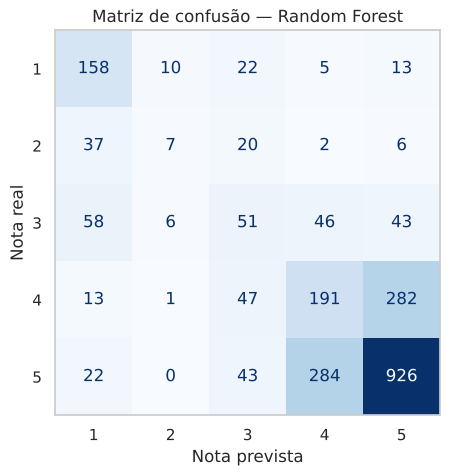

In [ ]:
modelos = {"Dummy (classe mais frequente)": dummy, "Árvore de Decisão": arvore, "Regressão Logística": logreg,
           "SVM (linear)": svm, "Rede Neural (MLP)": mlp, "Random Forest": rf, "Gradient Boosting (XGBoost)": xgb, "KNN": knn}
melhor = comp.index[0]
pred = modelos[melhor].predict(X_test)
print(f"Modelo final: {melhor}\n")
print(classification_report(y_test, pred, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Matriz de confusão — {melhor}"); ax.set_xlabel("Nota prevista"); ax.set_ylabel("Nota real"); ax.grid(False)
plt.show()

## 7. Conclusão

| Posição | Modelo | Etapa | F1-macro | Acurácia |
|---|---|---|---|---|
| 1º | **Random Forest** | visto em sala | 0,427 | 0,581 |
| 2º | SVM (linear) | visto em sala | 0,422 | 0,544 |
| 3º | Rede Neural (MLP) | visto em sala | 0,414 | 0,645 |
| 4º | Gradient Boosting (XGBoost) | não visto em sala | 0,412 | 0,638 |
| 5º | Regressão Logística | baseline | 0,400 | 0,640 |
| 6º | KNN | não visto em sala | 0,377 | 0,604 |
| 7º | Árvore de Decisão | baseline | 0,365 | 0,520 |
| — | Dummy (sempre nota 5) | referência | 0,143 | 0,556 |

* **Evolução em relação ao baseline:** SVM, Rede Neural, Random Forest e Gradient Boosting superaram os dois baselines no F1-macro. O ganho é moderado: de 0,400 (Regressão Logística) para 0,427.
* **Modelo final: Random Forest** (maior F1-macro). SVM, Rede Neural e Gradient Boosting ficaram muito próximos (diferença de até 0,015), praticamente empatados.
* **Modelos não vistos em sala:** o Gradient Boosting ficou no nível dos melhores. O KNN foi o mais fraco dos modelos novos: muitas reviews curtas e parecidas ("good", "nice") têm notas diferentes, então os vizinhos mais próximos nem sempre têm a mesma nota.
* **Rede Neural** teve a maior acurácia (0,645), mas acerta mais as notas frequentes (5) e menos as raras, por isso o F1-macro é um pouco menor.
* **Onde os modelos erram:** as notas extremas são bem reconhecidas (nota 1: F1 0,64; nota 5: F1 0,73), mas as intermediárias são difíceis, principalmente a nota 2 (só 2,8% dos dados). Como visto na análise da base, textos de notas 2, 3 e 4 misturam o vocabulário positivo e o negativo.
* **Cuidado importante:** removemos as avaliações repetidas antes de dividir os dados. Sem isso, 69% dos textos do teste também estavam no treino, e os modelos pareciam muito melhores (F1 ≈ 0,75) só porque "decoravam" as respostas, um caso de vazamento de dados.